In [6]:
#Importar las librerias necesarias para el proyecto
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 01. Data Cleaning

In [7]:
#Importar el dataset
df_HR = pd.read_csv('/content/Messy_HR_Dataset_Detailed.csv', index_col=0)
df_HR.index.name = None
df_HR

,FirstName,LastName,StartDate,ExitDate,Title,Supervisor,ADEmail,BusinessUnit,EmployeeStatus,EmployeeType,...,Satisfaction Score,Work-Life Balance Score,Training Date,Training Program Name,Training Type,Training Outcome,Location,Trainer,Training Duration(Days),Training Cost
0,Uriah,Bridges,20-Sep-19,NaN,Production Technician I,Peter Oneill,uriah.bridges@bilearner.com,CCDR,Active,Contract,...,2,3,15-Jul-23,Leadership Development,Internal,Failed,South Marisa,Taylor Rodriguez,2,606.11
1,Paula,Small,11-Feb-23,NaN,Production Technician I,Renee Mccormick,paula.small@bilearner.com,EW,Active,Contract,...,1,5,12-Sep-22,Customer Service,External,Incomplete,Tammieville,Kelly Patterson DDS,4,673.02
2,Edward,Buck,10-Dec-18,NaN,Area Sales Manager,Crystal Walker,edward.buck@bilearner.com,PL,Active,Full-Time,...,2,1,13-Aug-22,Leadership Development,External,Failed,East Roberthaven,Taylor Thomas,2,413.28
3,Michael,Riordan,21-Jun-21,NaN,Area Sales Manager,Rebekah Wright,michael.riordan@bilearner.com,CCDR,Active,Contract,...,5,4,15-Dec-22,Project Management,External,Completed,Garzatown,Holly Elliott,3,663.78
4,Jasmine,Onque,29-Jun-19,NaN,Area Sales Manager,Jason Kim,jasmine.onque@bilearner.com,TNS,Active,Contract,...,5,3,13-Jul-23,Technical Skills,External,Failed,Lake Meganville,Donald Martinez,5,399.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
450,Oscar,Lopez,22-Oct-18,07-Apr-20,Network Engineer,Christian Ortega,oscar.lopez@bilearner.com,MSC,Active,Part-Time,...,3,4,04-Jun-23,Communication Skills,External,Passed,Markhaven,Jeremy Townsend,1,888.55
2164,Cruz,Arellano,17-Sep-19,NaN,Area Sales Manager,Patricia Martinez,cruz.arellano@bilearner.com,SVG,Active,Full-Time,...,5,5,06-Oct-22,Customer Service,Internal,Completed,North Michaelbury,Jacob Johnson,2,745.31
2372,Makenna,Foster,20-Apr-21,17-Sep-22,Production Technician I,Timothy Pratt,makenna.foster@bilearner.com,CCDR,Active,Part-Time,...,1,1,28-Jul-23,Communication Skills,Internal,Incomplete,Stephaniemouth,Debbie Arnold,1,543.46
2012,Cordell,Vazquez,21-Aug-21,NaN,Production Manager,Paula Henderson,cordell.vazquez@bilearner.com,BPC,Active,Contract,...,3,5,29-Oct-22,Project Management,External,Failed,Port Joshuaborough,Shelby Fields,4,816.24


In [8]:
#Ver información básica del dataset
df_HR.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3150 entries, 0 to 270
Data columns (total 38 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   FirstName                   3150 non-null   object 
 1   LastName                    3150 non-null   object 
 2   StartDate                   3150 non-null   object 
 3   ExitDate                    1606 non-null   object 
 4   Title                       3150 non-null   object 
 5   Supervisor                  3150 non-null   object 
 6   ADEmail                     3150 non-null   object 
 7   BusinessUnit                3150 non-null   object 
 8   EmployeeStatus              3150 non-null   object 
 9   EmployeeType                3150 non-null   object 
 10  PayZone                     3150 non-null   object 
 11  EmployeeClassificationType  3150 non-null   object 
 12  TerminationType             3150 non-null   object 
 13  TerminationDescription      1606 non-nu

In [9]:
#Ver los duplicados del dataset ordenados por la columna 'ADEmail'
df_HR[df_HR.duplicated(keep=False)].sort_values(by='ADEmail')

,FirstName,LastName,StartDate,ExitDate,Title,Supervisor,ADEmail,BusinessUnit,EmployeeStatus,EmployeeType,...,Satisfaction Score,Work-Life Balance Score,Training Date,Training Program Name,Training Type,Training Outcome,Location,Trainer,Training Duration(Days),Training Cost
2528,Adison,Ray,21-Sep-20,22-Mar-23,Production Technician I,Carly Rogers,adison.ray@bilearner.com,PYZ,Active,Full-Time,...,2,3,04-Jun-23,Project Management,External,Failed,East Jimmy,Robin Banks,5,191.49
2528,Adison,Ray,21-Sep-20,22-Mar-23,Production Technician I,Carly Rogers,adison.ray@bilearner.com,PYZ,Active,Full-Time,...,2,3,04-Jun-23,Project Management,External,Failed,East Jimmy,Robin Banks,5,191.49
1770,Adrien,Maddox,22-Aug-18,10-Nov-21,Production Technician I,Tamara Humphrey,adrien.maddox@bilearner.com,SVG,Voluntarily Terminated,Contract,...,3,1,17-Mar-23,Technical Skills,External,Passed,Lake Jameschester,Harry Gibson,2,724.83
1770,Adrien,Maddox,22-Aug-18,10-Nov-21,Production Technician I,Tamara Humphrey,adrien.maddox@bilearner.com,SVG,Voluntarily Terminated,Contract,...,3,1,17-Mar-23,Technical Skills,External,Passed,Lake Jameschester,Harry Gibson,2,724.83
1820,Alessandra,Novak,10-Sep-18,08-Jun-23,IT Support,William Murray,alessandra.novak@bilearner.com,SVG,Active,Part-Time,...,4,4,19-Apr-23,Communication Skills,External,Incomplete,Barnettview,Tiffany Johnson,3,803.16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
194,Victoria,Franco,28-Nov-18,NaN,Production Technician I,Natalie Cannon,victoria.franco@bilearner.com,WBL,Active,Contract,...,3,2,15-Jul-23,Leadership Development,External,Passed,Lake Teresa,Frank Perry,3,879.89
63,Weston,Preston,11-Feb-19,NaN,Area Sales Manager,Crystal Wallace,weston.preston@bilearner.com,MSC,Active,Part-Time,...,3,2,19-Jul-23,Technical Skills,Internal,Failed,Lake Robertberg,Samantha Williams,3,389.59
63,Weston,Preston,11-Feb-19,NaN,Area Sales Manager,Crystal Wallace,weston.preston@bilearner.com,MSC,Active,Part-Time,...,3,2,19-Jul-23,Technical Skills,Internal,Failed,Lake Robertberg,Samantha Williams,3,389.59
644,Yadira,Mcmillan,28-Mar-19,17-Oct-20,Software Engineer,Amy Bell,yadira.mcmillan@bilearner.com,PL,Voluntarily Terminated,Contract,...,2,2,16-Mar-23,Communication Skills,Internal,Completed,Johnport,Amanda Medina,5,234.26


In [10]:
#Eliminar las columnas duplicadas y columnas que revelan datos personales de los empleados
df_HR = df_HR.drop_duplicates()
df_HR = df_HR.drop(columns=['FirstName', 'LastName', 'Employee ID', 'ADEmail'])

In [11]:
#Revisar valores nulos
df_HR.isnull().sum()

,0
StartDate,0
ExitDate,1467
Title,0
Supervisor,0
BusinessUnit,0
EmployeeStatus,0
EmployeeType,0
PayZone,0
EmployeeClassificationType,0
TerminationType,0


In [12]:
#Las columnas ExitDate y TerminationDescription tienen valores nulos porque no han abandonado el trabajo
df_HR[['EmployeeStatus', 'ExitDate', 'TerminationDescription']]

/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,EmployeeStatus,ExitDate,TerminationDescription
0,Active,NaN,NaN
1,Active,NaN,NaN
2,Active,NaN,NaN
3,Active,NaN,NaN
4,Active,NaN,NaN
...,...,...,...
2995,Leave of Absence,07-Aug-22,In forget fast.
2996,Active,NaN,NaN
2997,Voluntarily Terminated,04-Aug-22,Smile high bar white spend forget choice near.
2998,Voluntarily Terminated,23-Oct-21,Fine expect election either turn.


In [13]:
#Comprobar el formato de las columnas que contienen fechas
date_columns = ['StartDate', 'ExitDate', 'DOB','Survey Date', 'Training Date']
df_HR[date_columns].head(5)

,StartDate,ExitDate,DOB,Survey Date,Training Date
0,20-Sep-19,NaN,07-10-1969,14-01-2023,15-Jul-23
1,11-Feb-23,NaN,30-08-1965,09-09-2022,12-Sep-22
2,10-Dec-18,NaN,06-10-1991,27-05-2023,13-Aug-22
3,21-Jun-21,NaN,04-04-1998,16-06-2023,15-Dec-22
4,29-Jun-19,NaN,29-08-1969,25-11-2022,13-Jul-23


In [14]:
#Dar el mismo formato a todas las columnas que almancenan fechas
for col in date_columns:
  df_HR[col] = pd.to_datetime(df_HR[col], errors='coerce', dayfirst=True)

df_HR[date_columns].head(5)

/tmp/ipykernel_5585/1312175671.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_HR[col] = pd.to_datetime(df_HR[col], errors='coerce', dayfirst=True)
/tmp/ipykernel_5585/1312175671.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_HR[col] = pd.to_datetime(df_HR[col], errors='coerce', dayfirst=True)
/tmp/ipykernel_5585/1312175671.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_HR[col] = pd.to_datetime(df_HR[col], errors='coerce', dayfirst=True)


,StartDate,ExitDate,DOB,Survey Date,Training Date
0,2019-09-20,NaT,1969-10-07,2023-01-14,2023-07-15
1,2023-02-11,NaT,1965-08-30,2022-09-09,2022-09-12
2,2018-12-10,NaT,1991-10-06,2023-05-27,2022-08-13
3,2021-06-21,NaT,1998-04-04,2023-06-16,2022-12-15
4,2019-06-29,NaT,1969-08-29,2022-11-25,2023-07-13


In [15]:
#Eliminar espacios en blanco
for col in df_HR.select_dtypes(include='object').columns:
  df_HR[col] = df_HR[col].str.strip()

# 02. Exploratory Data Analysis

**1. ¿Cómo está distribuida la plantilla por departamento?**

In [16]:
Empleados_Departamento = df_HR['DepartmentType'].value_counts()
Porcentaje_Empleados = (Empleados_Departamento*100/Empleados_Departamento.sum()).round(2)
Distribucion_Empleados = pd.DataFrame({
    'Total Empleados': Empleados_Departamento,
    'Porcentaje Empleados': Porcentaje_Empleados
})
Distribucion_Empleados

,Total Empleados,Porcentaje Empleados
DepartmentType,,
Production,2020,67.33
IT/IS,430,14.33
Sales,331,11.03
Software Engineering,115,3.83
Admin Offices,80,2.67
Executive Office,24,0.80


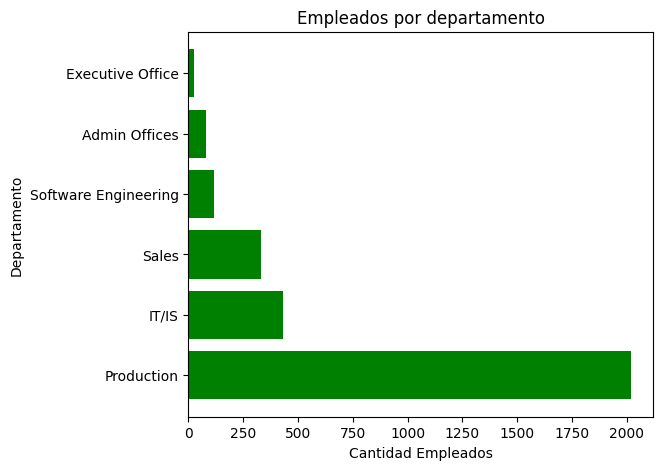

In [17]:
plt.figure(figsize=(6,5))

plt.barh(Empleados_Departamento.index, Empleados_Departamento.values, color='green')
plt.xlabel('Cantidad Empleados')
plt.ylabel('Departamento')
plt.title('Empleados por departamento')

plt.show()

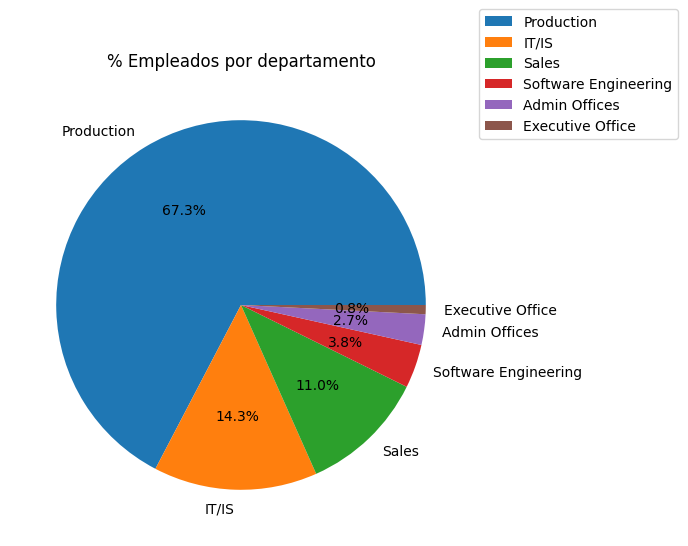

In [18]:
plt.figure(figsize=(8,6))

plt.pie(Porcentaje_Empleados, labels=Porcentaje_Empleados.index, autopct='%1.1f%%')
plt.legend(loc='center left', bbox_to_anchor=(1, 1))
plt.title('% Empleados por departamento')

plt.show()

La plantilla está fuertemente concentrada en el departamento de Production, que reúne más de dos tercios de los empleados de la empresa (67.3%). A bastante distancia se encuentran IT/IS y Sales, mientras que el resto de departamentos tienen una representación mucho menor. Esto sugiere que la organización tiene un perfil principalmente operativo, con gran parte de su fuerza laboral enfocada en actividades de producción.

**02. ¿Qué departamentos presentan empleados más satisfechos y comprometidos?**

In [19]:
df_HR.groupby('DepartmentType')[['Satisfaction Score', 'Engagement Score']].mean().round(2).sort_values(by='Satisfaction Score', ascending=False)

,Satisfaction Score,Engagement Score
DepartmentType,,
Sales,3.13,2.99
Software Engineering,3.11,2.97
Executive Office,3.08,3.38
Production,3.02,2.91
IT/IS,3.01,3.03
Admin Offices,2.51,2.92


El departamento de Sales presenta el mayor nivel medio de satisfacción laboral (3.13), mientras que Executive Office registra el mayor nivel de engagement (3.38). Por otro lado, Admin Offices obtiene los valores más bajos en ambas métricas y muestra una diferencia especialmente notable en satisfacción respecto al resto de departamentos. Estos resultados sugieren que la experiencia de los empleados varía según el área de la organización y que satisfacción y engagement no siempre evolucionan de forma conjunta.

**03. ¿En qué estados tienen los hombres y las mujeres las mejores evaluaciones de desempeño?**

In [20]:
df_hombres = df_HR[df_HR['GenderCode']=='Male']
df_mujeres = df_HR[df_HR['GenderCode']=='Female']

In [21]:
cantidad_hombres = df_hombres['State'].value_counts()
cantidad_mujeres = df_mujeres['State'].value_counts()

cantidad_hombres = cantidad_hombres[cantidad_hombres>10]
cantidad_mujeres = cantidad_mujeres[cantidad_mujeres>10]

In [22]:
df_hombres = df_hombres[df_hombres['State'].isin(cantidad_hombres.index)]
df_mujeres = df_mujeres[df_mujeres['State'].isin(cantidad_mujeres.index)]

rating_hombres = df_hombres.groupby('State')['Current Employee Rating'].mean().round(2).sort_values(ascending=False).head(5)
rating_mujeres = df_mujeres.groupby('State')['Current Employee Rating'].mean().round(2).sort_values(ascending=False).head(5)

In [23]:
rating_hombres.rename(index={'ID': 'Idaho', 'CO': 'Colorado', 'AZ': 'Arizona', 'TX': 'Texas', 'MA': 'Massachusetts'}, inplace=True)
rating_mujeres.rename(index={'CT': 'Connecticut', 'MA': 'Massachusetts', 'WA': 'Washington', 'PA': 'Pennsylvania', 'KY': 'Kentucky'}, inplace=True)

tabla_resumen = pd.DataFrame({
    'Estado Hombres': rating_hombres.index,
    'Rating Hombres': rating_hombres.values,
    'Estado Mujeres': rating_mujeres.index,
    'Rating Mujeres': rating_mujeres.values
})
tabla_resumen

,Estado Hombres,Rating Hombres,Estado Mujeres,Rating Mujeres
0,Idaho,3.10,Connecticut,3.23
1,Colorado,3.04,Massachusetts,3.00
2,Arizona,3.04,Washington,3.00
3,Texas,3.00,Pennsylvania,3.00
4,Massachusetts,2.95,Kentucky,2.77


Entre los hombres, Idaho registra la valoración media más alta (3.10), seguido de Colorado y Arizona. En el caso de las mujeres, Connecticut lidera el ranking con una puntuación de 3.23. También destaca Massachusetts, que aparece entre los cinco estados con mejores valoraciones para ambos grupos. En general, los estados mejor valorados no coinciden entre hombres y mujeres, lo que sugiere diferencias geográficas en las evaluaciones de desempeño.

**04. ¿Cómo varía el nivel de Performance según la antigüedad de los empleados?**

In [24]:
hoy = pd.Timestamp.today()
df_HR['Tenure_Years'] = np.where(df_HR['EmployeeStatus'] == 'Active',
         ((hoy - df_HR['StartDate']).dt.days/365).round(2),
         ((df_HR['ExitDate'] - df_HR['StartDate']).dt.days/365).round(2))

df_HR['Tenure_Group'] = pd.cut(df_HR['Tenure_Years'], bins=[0,2,4,6,8, float('inf')],
       labels=['0-2 años', '2-4 años', '4-6 años', '6-8 años', 'más de 8 años'])

df_HR[['Tenure_Years', 'Tenure_Group']]

,Tenure_Years,Tenure_Group
0,7.13,6-8 años
1,3.74,2-4 años
2,7.91,6-8 años
3,5.38,4-6 años
4,7.36,6-8 años
...,...,...
2995,0.13,0-2 años
2996,5.86,4-6 años
2997,1.65,0-2 años
2998,2.41,2-4 años


In [25]:
tenure_performance = (pd.crosstab(df_HR['Tenure_Group'], df_HR['Performance Score'], normalize='index')*100).round(2)
tenure_performance

Performance Score,Exceeds,Fully Meets,Needs Improvement,PIP
Tenure_Group,,,,
0-2 años,10.80,79.43,6.17,3.60
2-4 años,12.09,77.78,6.04,4.09
4-6 años,11.59,80.22,5.39,2.80
6-8 años,13.90,77.96,5.77,2.37
más de 8 años,11.29,73.39,9.68,5.65


In [26]:
tenure_performance = tenure_performance[['Fully Meets', 'Exceeds', 'Needs Improvement', 'PIP']]
tenure_performance

Performance Score,Fully Meets,Exceeds,Needs Improvement,PIP
Tenure_Group,,,,
0-2 años,79.43,10.80,6.17,3.60
2-4 años,77.78,12.09,6.04,4.09
4-6 años,80.22,11.59,5.39,2.80
6-8 años,77.96,13.90,5.77,2.37
más de 8 años,73.39,11.29,9.68,5.65


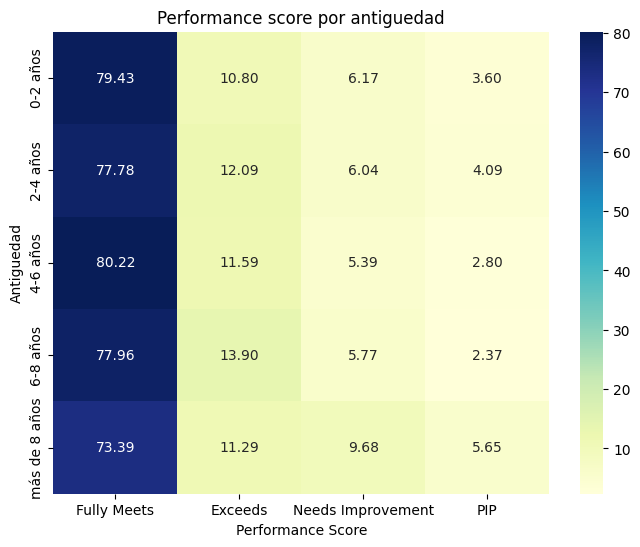

In [27]:
plt.figure(figsize=(8,6))
sns.heatmap(
    tenure_performance,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu'
)

plt.title('Performance score por antiguedad')
plt.ylabel('Antiguedad')
plt.show()

En todos los grupos de antigüedad, la mayoría de los empleados se encuentra en la categoría "Fully Meets", por lo que el nivel de desempeño general se mantiene bastante estable. Sin embargo, los empleados con entre 6 y 8 años de antigüedad destacan por tener la mayor proporción de evaluaciones "Exceeds", lo que sugiere que suelen encontrarse en un momento de madurez profesional dentro de la empresa. Por otro lado, en el grupo de más de 8 años aumenta la presencia de evaluaciones "Needs Improvement" y "PIP", lo que indica que una mayor antigüedad no siempre va acompañada de un mejor rendimiento.

**05. ¿Qué caracteriza a los empleados que abandonan la empresa?**

In [28]:
permanece = ['Active', 'Leave of Absence', 'Future Start']
abandona = ['Voluntarily Terminated', 'Terminated for Cause']
df_HR['Attrition Status'] = df_HR['EmployeeStatus'].apply(lambda x: 1 if x in(abandona) else 0)
df_HR['Attrition Status'].value_counts(normalize=True)*100

,proportion
Attrition Status,
0,87.1
1,12.9


In [29]:
diferencia_attrition =df_HR.groupby('Attrition Status')[['Tenure_Years', 'Satisfaction Score', 'Engagement Score', 'Current Employee Rating']].mean()
diferencia_attrition.rename(index={0: 'Permanece', 1: 'Abandona'}, inplace=True)
diferencia_attrition

,Tenure_Years,Satisfaction Score,Engagement Score,Current Employee Rating
Attrition Status,,,,
Permanece,5.481083,3.007654,2.945656,2.953693
Abandona,1.420181,3.118863,2.899225,3.072351


La principal diferencia entre los empleados que permanecen en la empresa y quienes la abandonan se encuentra en la antigüedad. Los empleados que continúan en la organización acumulan, de media, más de 5 años de permanencia, mientras que quienes abandonan la empresa apenas superan el año de antigüedad. Esto sugiere que la mayor parte de las salidas se produce durante los primeros años de la relación laboral.

En cambio, las diferencias en satisfacción, engagement y evaluación de desempeño son mínimas. Los empleados que abandonan la empresa presentan niveles muy similares, e incluso ligeramente superiores, a los de quienes permanecen. Por ello, en este conjunto de datos no parece existir una relación clara entre estas variables y la decisión de abandonar la organización.

# 03. Machine Learning

In [30]:
#Se realiza una copia del dataset original para la etapa de ML
df_HR_2 = df_HR.copy()
df_HR_2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3000 entries, 0 to 2999
Data columns (total 37 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   StartDate                   3000 non-null   datetime64[ns]
 1   ExitDate                    1533 non-null   datetime64[ns]
 2   Title                       3000 non-null   object        
 3   Supervisor                  3000 non-null   object        
 4   BusinessUnit                3000 non-null   object        
 5   EmployeeStatus              3000 non-null   object        
 6   EmployeeType                3000 non-null   object        
 7   PayZone                     3000 non-null   object        
 8   EmployeeClassificationType  3000 non-null   object        
 9   TerminationType             3000 non-null   object        
 10  TerminationDescription      1533 non-null   object        
 11  DepartmentType              3000 non-null   object        
 1

In [31]:
#Se revisa la distribución de la variable objetivo
df_HR_2['Attrition Status'].value_counts(normalize=True)

,proportion
Attrition Status,
0,0.871
1,0.129


In [32]:
#Se crea la variable Age a partir de DOB
df_HR_2['Age'] = ((hoy - df_HR_2['DOB']).dt.days/365).round(0)
df_HR_2 = df_HR_2.drop(columns=df_HR_2.select_dtypes(include='datetime64[ns]').columns)

In [33]:
#Se comprueba la cardinalidad de las variables categoricas
for col in df_HR_2.select_dtypes(include='object').columns:
  cardinalidad = df_HR_2[col].nunique()
  print(f'{col}: {cardinalidad} columnas')

Title: 31 columnas
Supervisor: 2952 columnas
BusinessUnit: 10 columnas
EmployeeStatus: 5 columnas
EmployeeType: 3 columnas
PayZone: 3 columnas
EmployeeClassificationType: 3 columnas
TerminationType: 5 columnas
TerminationDescription: 1533 columnas
DepartmentType: 6 columnas
Division: 25 columnas
State: 28 columnas
JobFunctionDescription: 83 columnas
GenderCode: 2 columnas
RaceDesc: 5 columnas
MaritalDesc: 4 columnas
Performance Score: 4 columnas
Training Program Name: 5 columnas
Training Type: 2 columnas
Training Outcome: 4 columnas
Location: 2738 columnas
Trainer: 2942 columnas


In [34]:
#Eliminar columnas que tienen una cardinalidad muy alta, información redundante o que puedan provocar data leak
df_HR_2 = df_HR_2.drop(columns=['Supervisor', 'TerminationDescription', 'JobFunctionDescription', 'Location', 'Trainer', 'Tenure_Group', 'EmployeeStatus', 'LocationCode', 'TerminationType'])

In [35]:
#Se separan las variables categóricas de las numéricas para realizar el analisis adecuado a cada tipo de dato
variables_numericas = [col for col in df_HR_2.select_dtypes(include=['int64', 'float64']) if col != 'Attrition Status']
variables_categoricas = [col for col in df_HR_2.select_dtypes(include='object')]
print(variables_numericas)
print(variables_categoricas)

['Current Employee Rating', 'Engagement Score', 'Satisfaction Score', 'Work-Life Balance Score', 'Training Duration(Days)', 'Training Cost', 'Tenure_Years', 'Age']
['Title', 'BusinessUnit', 'EmployeeType', 'PayZone', 'EmployeeClassificationType', 'DepartmentType', 'Division', 'State', 'GenderCode', 'RaceDesc', 'MaritalDesc', 'Performance Score', 'Training Program Name', 'Training Type', 'Training Outcome']


In [36]:
#Se compara la media de las variables numericas entre los empleados que permanecen y los que abandonan la empresa
df_HR_2.groupby('Attrition Status')[variables_numericas].mean()

,Current Employee Rating,Engagement Score,Satisfaction Score,Work-Life Balance Score,Training Duration(Days),Training Cost,Tenure_Years,Age
Attrition Status,,,,,,,,
0,2.953693,2.945656,3.007654,3.002679,2.974742,560.217501,5.481083,55.185993
1,3.072351,2.899225,3.118863,2.896641,2.981912,547.901189,1.420181,55.263566


La diferencia más clara entre ambos grupos aparece en la antigüedad. Los empleados que permanecen en la empresa tienen en promedio más de cinco años de permanencia, mientras que los que abandonan la organización apenas superan el año. Esto indica que la mayor parte de las bajas se concentra durante los primeros años de la relación laboral.

En cambio, variables como la satisfacción, el engagement, la edad o el coste de formación presentan valores bastante similares entre ambos grupos. Aunque algunas muestran pequeñas diferencias, ninguna resulta tan marcada como la observada en la antigüedad, lo que la convierte en una de las variables más prometedoras para explicar el abandono de empleados.

In [37]:
#Se crea una lista con las variables que se van a eliminar
eliminar_var = ['Training Duration(Days)', 'Work-Life Balance Score']

In [38]:
#Se compara la tasa de abandono en las diferentes variables categoricas
for col in variables_categoricas:
    print(f"\n{'='*50}")
    print(f"VARIABLE: {col}")
    print(f"{'='*50}")

    attrition_por_categoria = pd.crosstab(
            df_HR_2[col],
            df_HR_2['Attrition Status'],
            normalize='index'
        ) * 100
    attrition_por_categoria = attrition_por_categoria.rename(columns={0:'Permanece', 1:'Abandona'})
    print(attrition_por_categoria.round(2))


VARIABLE: Title
Attrition Status              Permanece  Abandona
Title                                            
Accountant I                     100.00      0.00
Administrative Assistant          96.97      3.03
Area Sales Manager                99.66      0.34
BI Developer                      72.73     27.27
BI Director                       63.64     36.36
CIO                               63.64     36.36
Data Analyst                      96.36      3.64
Data Architect                    20.00     80.00
Database Administrator            76.00     24.00
Director of Operations           100.00      0.00
Director of Sales                100.00      0.00
Enterprise Architect              80.00     20.00
IT Director                      100.00      0.00
IT Manager - DB                  100.00      0.00
IT Manager - Infra               100.00      0.00
IT Manager - Support             100.00      0.00
IT Support                       100.00      0.00
Network Engineer                 

Las diferencias más marcadas en la tasa de abandono aparecen en variables como Title, DepartmentType y Division, donde algunas categorías presentan porcentajes de abandono superiores al promedio. En cambio, variables como BusinessUnit, EmployeeType, EmployeeClassificationType, PayZone, RaceDesc, MaritalDesc y Training Type muestran comportamientos muy parecidos entre sus categorías, lo que indica que puede haber una menor capacidad para explicar el abandono de empleados.

In [39]:
#Se eliminan las variables seleccionadas
eliminar_var.extend(['BusinessUnit', 'EmployeeType', 'EmployeeClassificationType', 'PayZone','MaritalDesc', 'Training Type', 'RaceDesc', 'Training Outcome'])
df_HR_2.drop(columns=eliminar_var, inplace=True)

#Se actualizan las listas que contienen las variables
variables_numericas = [col for col in df_HR_2.select_dtypes(include=['int64', 'float64']) if col != 'Attrition Status']
variables_categoricas = [col for col in df_HR_2.select_dtypes(include='object')]

In [40]:
df_HR_2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3000 entries, 0 to 2999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Title                    3000 non-null   object 
 1   DepartmentType           3000 non-null   object 
 2   Division                 3000 non-null   object 
 3   State                    3000 non-null   object 
 4   GenderCode               3000 non-null   object 
 5   Performance Score        3000 non-null   object 
 6   Current Employee Rating  3000 non-null   int64  
 7   Engagement Score         3000 non-null   int64  
 8   Satisfaction Score       3000 non-null   int64  
 9   Training Program Name    3000 non-null   object 
 10  Training Cost            3000 non-null   float64
 11  Tenure_Years             3000 non-null   float64
 12  Attrition Status         3000 non-null   int64  
 13  Age                      3000 non-null   float64
dtypes: float64(3), int64(4), obje

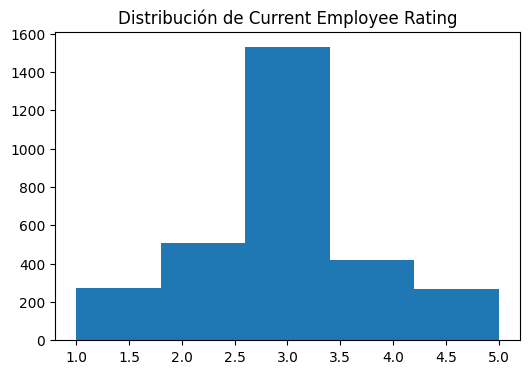

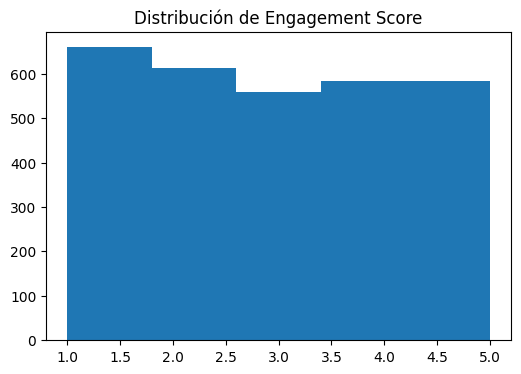

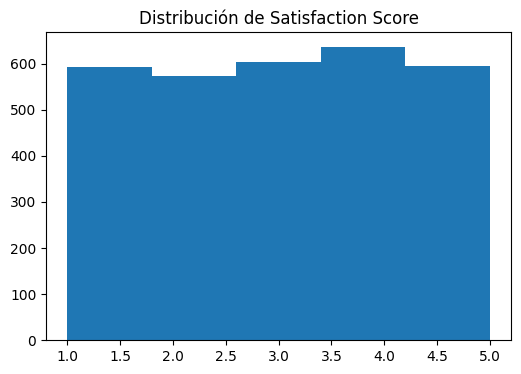

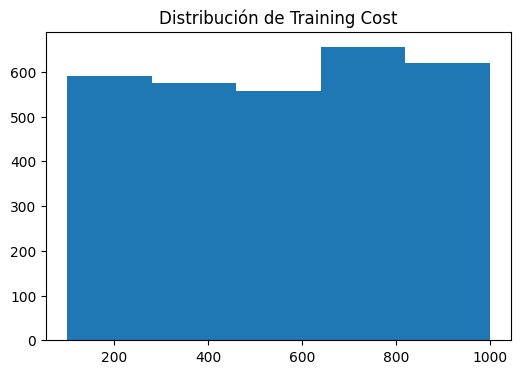

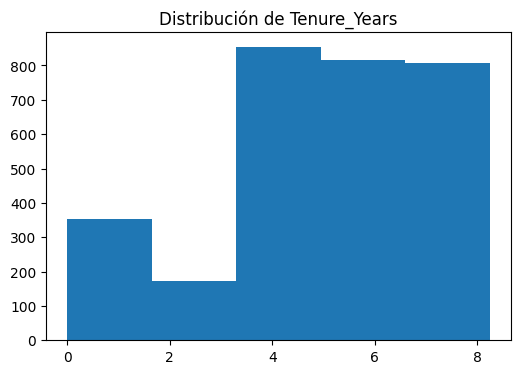

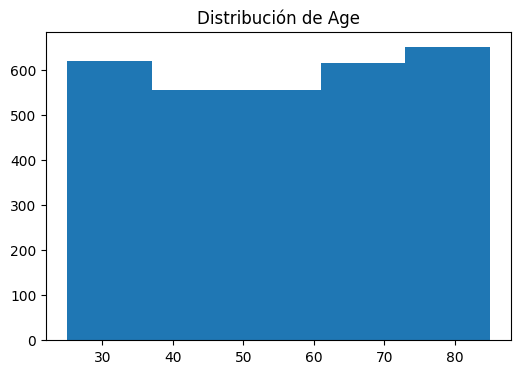

In [41]:
#Se revisa la distribucion de las variables numéricas
for col in variables_numericas:
  plt.figure(figsize=(6,4))
  plt.hist(df_HR_2[col], bins=5)
  plt.title('Distribución de ' + col)
  plt.show()

La mayoría de las variables numéricas tiene distribuciones bastante equilibradas y sin sesgos pronunciados. Destaca Current Employee Rating, donde la mayor parte de los empleados se concentra alrededor de una valoración media, y Tenure_Years, que muestra una mayor presencia de empleados con varios años de antigüedad.

In [42]:
#Se separan las variables predictorias de la variable objetivo
X = df_HR_2.copy()
X = X.drop(columns='Attrition Status')
Y = df_HR_2['Attrition Status']

In [43]:
#Se definen las transformaciones para las variables
scaler = StandardScaler()
enc = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
preprocessor = ColumnTransformer(
    transformers=[('num', scaler, variables_numericas),
                  ('cat', enc, variables_categoricas)]
)

In [44]:
#Se aplican las transformaciones antes del entrenamiento de los modelos
X_prepared = preprocessor.fit_transform(X)
X_prepared

array([[ 1.01585525, -1.35339347, -0.72553784, ...,  1.        ,
         0.        ,  0.        ],
       [ 0.03054463, -0.65564808, -1.43545746, ...,  0.        ,
         0.        ,  0.        ],
       [ 1.01585525, -1.35339347, -0.72553784, ...,  1.        ,
         0.        ,  0.        ],
       ...,
       [-0.954766  , -0.65564808,  0.69430138, ...,  0.        ,
         1.        ,  0.        ],
       [-0.954766  ,  1.43758808, -0.72553784, ...,  0.        ,
         0.        ,  1.        ],
       [-0.954766  , -1.35339347, -0.01561823, ...,  1.        ,
         0.        ,  0.        ]], shape=(3000, 107))

In [45]:
#Se realiza la division en datos de entrenamiento y de test
X_train, X_test, y_train, y_test = train_test_split(X_prepared, Y, test_size=0.2, random_state=42, stratify=Y)

In [52]:
#Se realiza el entrenamiento de un modelo Logistic Regression y se analiza los resultados con diferentes métricas
lr = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))

Accuracy: 0.9316666666666666
Precision: 0.6698113207547169
Recall: 0.922077922077922
F1 Score: 0.7759562841530054


* Como el objetivo principal es identificar a los empleados que podrían abandonar la empresa, la métrica más importante es el Recall. Esta métrica indica qué tan bien el modelo logra detectar los casos reales de abandono, permitiendo identificar a la mayor cantidad posible de empleados en riesgo y reducir los casos que pasan desapercibidos.

* Este modelo alcanzó un Recall de **92.20%**, lo que significa que identifica correctamente más de 9 de cada 10 empleados que realmente abandonan la empresa, siendo un resultado muy favorable para este tipo de problema.

* Su Precision fue del **66.98%**, es decir clasifica a algunos empleados como abandono cuando corresponden a empleados que finalmente permanecen, aunque esto suele ser preferible a no detectar casos reales de salida.

* Además, obtuvo un F1-Score de **77.59%** y una Accuracy de **93.16%**, reflejando un desempeño general sólido.

In [45]:
#Se realiza la matriz de confusión para analizar la capacidad del modelo de identificar a los que abandonan y permanecen
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr
)

print(cm_lr)

[[488  35]
 [  6  71]]


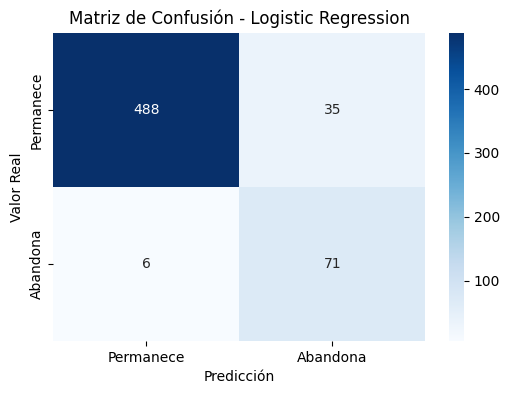

In [46]:
#Se realiza un heatmap de la matriz de confusión para una mejor visualización
plt.figure(figsize=(6,4))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Permanece', 'Abandona'],
    yticklabels=['Permanece', 'Abandona']
)

plt.title('Matriz de Confusión - Logistic Regression')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')

plt.show()

La matriz de confusión muestra que el modelo de Logistic Regresion tiene un buen desempeño, ya que clasifica correctamente la mayoría de los casos (559 en total). Además, identifica bien a los estudiantes que permanecen y a los que abandonan. Sin embargo, se observan más errores al predecir abandono en estudiantes que realmente permanecen (35 casos) que al contrario (6 casos), lo que indica que el modelo tiende a ser no tan bueno al detectar posibles abandonos.

In [54]:
#Se realiza el entrenamiento de un modelo XGBOOST y se analiza los resultados con diferentes métricas
xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)


print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1 Score:", f1_score(y_test, y_pred_xgb))

Accuracy: 0.9383333333333334
Precision: 0.7439024390243902
Recall: 0.7922077922077922
F1 Score: 0.7672955974842768


* El modelo XGBoost obtuvo un Recall de **79.22%**, lo que significa que identifica correctamente cerca de 8 de cada 10 empleados que realmente abandonan la empresa. Aunque es un buen resultado, deja sin detectar una mayor cantidad de casos de abandono en comparación con el modelo de Logistic Regresion.

* Su Precision fue de **74.39%** es superior a la de la Regresión Logística, lo que indica que las predicciones de abandono son más fiables y generan menos falsas alarmas.

* Además, alcanzó un F1-Score de **76.73%** y una Accuracy de **93.83%**, mostrando un desempeño general sólido y equilibrado.

Sin embargo, dado que el objetivo principal es detectar la mayor cantidad posible de empleados con riesgo de abandono, el Recall de XGBoost es inferior al de la Regresión Logística (79.22% vs 92.21%), por lo que podría no ser la mejor opción para este caso.

In [66]:
#Se realiza la matriz de confusión para analizar la capacidad del modelo de identificar a los que abandonan y permanecen
cm_xgb = confusion_matrix(
    y_test,
    y_pred_xgb
)

print(cm_xgb)

[[502  21]
 [ 16  61]]


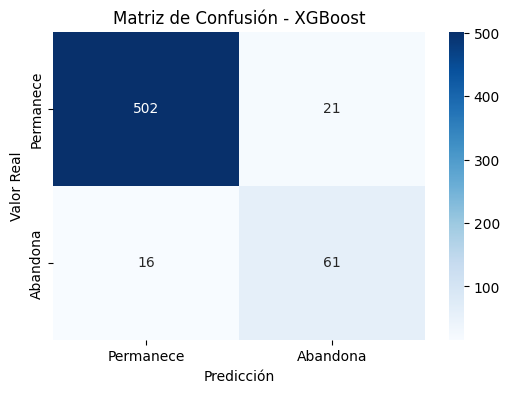

In [69]:
#Se realiza un heatmap de la matriz de confusión para una mejor visualización
plt.figure(figsize=(6,4))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Permanece', 'Abandona'],
    yticklabels=['Permanece', 'Abandona']
)

plt.title('Matriz de Confusión - XGBoost')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')

plt.show()

La matriz de confusión muestra que el modelo XGBoost presenta un buen desempeño, ya que, identifica de manera correcta a la mayoria de los estudiantes que permanecen y a los que abandonan, aunque aún se observan algunos errores de clasificación. En general, el modelo demuestra una alta capacidad predictiva.

In [48]:
#Se analiza la importancia de las variables a la hora de realizar la predicción de abandono de los empleados
importance = pd.DataFrame({
    'Feature': preprocessor.get_feature_names_out(),
    'Importance': xgb.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

importance.head(10)

,Feature,Importance
4,num__Tenure_Years,0.160569
8,cat__Title_Area Sales Manager,0.134454
36,cat__Title_Sr. Network Engineer,0.119237
62,cat__Division_Splicing,0.038763
39,cat__DepartmentType_IT/IS,0.030016
43,cat__Division_Aerial,0.029068
9,cat__Title_BI Developer,0.025587
32,cat__Title_Software Engineer,0.025543
53,cat__Division_General - Eng,0.022265
26,cat__Title_Production Manager,0.021330


El análisis de feature importance muestra que la antigüedad del empleado es el factor que más influye en la predicción del abandono. Esto sugiere que los trabajadores con menos tiempo en la empresa tienen una mayor probabilidad de renunciar, especialmente durante sus primeros años.

También se observa que algunos puestos específicos, como Area Sales Manager y Sr. Network Engineer, tienen una influencia importante en el modelo, lo que indica que el riesgo de rotación puede variar según el cargo desempeñado. De igual manera, ciertas áreas y departamentos, como Splicing e IT/IS, aparecen entre las variables más relevantes.

En general, los resultados indican que el abandono laboral está relacionado principalmente con la experiencia del empleado dentro de la empresa, el puesto que ocupa y el área donde trabaja. Por ello, sería recomendable enfocar las estrategias de retención en los colaboradores con menor antigüedad y en aquellos cargos o áreas que presentan una mayor tendencia a la rotación.